# Notebook 02: Christoffel Symbols, Riemann Tensor, and Gaussian Curvature Flow Across Layers

## Research Objective
We compute the Levi-Civita connection (Christoffel symbols $\Gamma^{(\ell)k}_{ij}$) and intrinsic **Gaussian curvature** $K^{(\ell)}(x; \theta)$ of the 2D immersed representation manifolds $\mathcal{M}_\ell = \Phi^{(\ell)}_\theta(\mathbb{R}^2) \subset \mathbb{R}^{d_\ell}$ across layers $\ell \in \{1, 2, 3, 4, 5\}$:
$$\Gamma^{(\ell)}_{kij} = \frac{1}{2}\left(\partial_j g^{(\ell)}_{ki} + \partial_i g^{(\ell)}_{kj} - \partial_k g^{(\ell)}_{ij}\right), \qquad R^{(\ell)}_{1212} = -\frac{1}{2}\left(\partial_1^2 g^{(\ell)}_{22} - 2\partial_1\partial_2 g^{(\ell)}_{12} + \partial_2^2 g^{(\ell)}_{11}\right) + g^{(\ell)km}\left(\Gamma^{(\ell)}_{k12}\Gamma^{(\ell)}_{m12} - \Gamma^{(\ell)}_{k11}\Gamma^{(\ell)}_{m22}\right)$$
$$K^{(\ell)}(x) = \frac{R^{(\ell)}_{1212}(x)}{\det g^{(\ell)}(x)}, \qquad R_{\text{scalar}}^{(\ell)}(x) = 2 K^{(\ell)}(x)$$

### Key Mathematical Insight: The 2D-to-2D Euclidean Pullback Flatness Identity at Layer $\ell = 5$
- For hidden layers $\ell \in \{1, 2, 3, 4\}$ ($d_\ell \in \{5, 10, 15, 10\} > 2$), $\mathcal{M}_\ell$ is a 2D surface immersed in higher-dimensional Euclidean space $\mathbb{R}^{d_\ell}$, possessing rich non-zero intrinsic Gaussian curvature $K^{(\ell)}(x) \neq 0$.
- At the output layer $\ell = 5$ ($d_5 = 2$), pulling back the flat 2D Euclidean metric $I_2$ via a local diffeomorphism $z = f_\theta(x) \in \mathbb{R}^2$ is merely a coordinate change of flat Euclidean space, so $K^{(5)}_{\text{eucl}}(x) \equiv 0$!
- We empirically verify this identity and compare three non-degenerate output curvature constructions:
  1. **Graph Embedding Metric (Monge Patch in $\mathbb{R}^4$)**: $\tilde{g}^{(5)}_{ij}(x) = \delta_{ij} + ((J^{(5)}(x))^T J^{(5)}(x))_{ij}$.
  2. **Conformal Gaussian Output Metric**: $g^{(5)}_{\text{conf}}(x) = e^{-\|z(x)\|^2 / \sigma^2} (J^{(5)}(x))^T J^{(5)}(x)$.
  3. **Penultimate Surface Metric**: $g^{(4)}_{\text{eucl}}(x)$ on $\mathcal{M}_4 \subset \mathbb{R}^{10}$.

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd(), Path.cwd().parent]:
    if (p / "src" / "geometry.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from src.geometry import (
    MoonsMLP,
    get_moons_dataset,
    make_evaluation_grid,
    compute_layer_geometry,
    _christoffel_and_curvature_from_g_single,
)

X_train, y_train, X_test, y_test = get_moons_dataset(n_train=360, n_test=180, noise=0.10, seed=42)
xx, yy, grid_pts = make_evaluation_grid(X_train, n_grid=26, padding=0.45)

# 1. Analytical validation on a sphere of radius R=2 (K = 1/R^2 = 0.25) and hyperbolic paraboloid (K(0) = -3.0)
R_s = 2.0
g_sphere = lambda x: ((2.0 * R_s**2 / (R_s**2 + torch.sum(x**2)))**2) * torch.eye(2, dtype=x.dtype)
_, _, _, K_sphere = _christoffel_and_curvature_from_g_single(g_sphere)(torch.tensor([0.8, -0.6], dtype=torch.float64))

g_saddle = lambda x: torch.eye(2, dtype=x.dtype) + torch.stack([2.0 * x[0], -1.5 * x[1]]).unsqueeze(0).T @ torch.stack([2.0 * x[0], -1.5 * x[1]]).unsqueeze(0)
_, _, _, K_saddle = _christoffel_and_curvature_from_g_single(g_saddle)(torch.zeros(2, dtype=torch.float64))

print(f"Analytical Validation | Sphere (R=2) exact K=0.250000 -> autodiff K={K_sphere.item():.6f}")
print(f"Analytical Validation | Hyperbolic Saddle exact K(0)=-3.000000 -> autodiff K={K_saddle.item():.6f}")

Analytical Validation | Sphere (R=2) exact K=0.250000 -> autodiff K=0.250000
Analytical Validation | Hyperbolic Saddle exact K(0)=-3.000000 -> autodiff K=-3.000000


## 1. Empirical Verification of 2D-to-2D Euclidean Flatness vs. Non-Degenerate Output Metrics
We train our `[2 -> 5 -> 10 -> 15 -> 10 -> 2]` MLP and compare the four curvature definitions at the output/penultimate layers.

In [2]:
model = MoonsMLP(layer_dims=(2, 5, 10, 15, 10, 2), activation="tanh", seed=42)
optimizer = torch.optim.Adam(model.parameters(), lr=0.015)
criterion = nn.CrossEntropyLoss()

epoch_snapshots = {0: copy.deepcopy(model.state_dict())}
for ep in range(1, 201):
    optimizer.zero_grad()
    loss = criterion(model(X_train), y_train)
    loss.backward()
    optimizer.step()
    if ep in [20, 70, 200]:
        epoch_snapshots[ep] = copy.deepcopy(model.state_dict())

geom_l5_eucl = compute_layer_geometry(model, X_test[:50], layer_idx=5, metric_mode="euclidean", eps=1e-13)
geom_l5_graph = compute_layer_geometry(model, X_test[:50], layer_idx=5, metric_mode="graph")
geom_l5_conf = compute_layer_geometry(model, X_test[:50], layer_idx=5, metric_mode="conformal_gaussian", sigma=2.5)
geom_l4_eucl = compute_layer_geometry(model, X_test[:50], layer_idx=4, metric_mode="euclidean", eps=1e-7)

print("Comparison of Curvature Formulations on Trained Network (50 test points):")
print(f"  1. Layer 5 Flat Euclidean Pullback (d=2 -> d=2) : max |K| = {geom_l5_eucl['K'].abs().max().item():.2e} (Identically Flat!)")
print(f"  2. Layer 5 Graph Immersion Metric in R^4        : mean |K| = {geom_l5_graph['K'].abs().mean().item():.4f}, range = [{geom_l5_graph['K'].min().item():.3f}, {geom_l5_graph['K'].max().item():.3f}]")
print(f"  3. Layer 5 Conformal Gaussian Output Metric     : mean |K| = {geom_l5_conf['K'].abs().mean().item():.4f}, range = [{geom_l5_conf['K'].min().item():.3f}, {geom_l5_conf['K'].max().item():.3f}]")
print(f"  4. Layer 4 Penultimate Immersion in R^10        : mean |K| = {geom_l4_eucl['K'].abs().mean().item():.4f}, range = [{geom_l4_eucl['K'].min().item():.3f}, {geom_l4_eucl['K'].max().item():.3f}]")

Comparison of Curvature Formulations on Trained Network (50 test points):
  1. Layer 5 Flat Euclidean Pullback (d=2 -> d=2) : max |K| = 1.21e-05 (Identically Flat!)
  2. Layer 5 Graph Immersion Metric in R^4        : mean |K| = 0.2061, range = [-0.362, 4.610]
  3. Layer 5 Conformal Gaussian Output Metric     : mean |K| = 52489.6960, range = [-178503.966, 790900.828]
  4. Layer 4 Penultimate Immersion in R^10        : mean |K| = 1.5564, range = [-4.730, 24.755]


## 2. Layerwise Gaussian Curvature Landscape $K^{(\ell)}(x)$ Across Network Depth
We plot $\mathrm{arcsinh}(K^{(\ell)}(x))$ across layers $\ell = 1, 2, 3, 4$ (Euclidean immersion in $\mathbb{R}^{d_\ell}$) and layer $\ell = 5$ (Graph immersion in $\mathbb{R}^4$).
Notice how **Brandon, Chadwick, & Pellegrino (2025)**'s two-stage geometric decomposition appears:
- **Early expansion layers ($\ell = 1, 2, 3$)** introduce localized positive and negative curvature folds along the moon crescents to discretize continuous input coordinates.
- **Contraction layers ($\ell = 4, 5$)** concentrate sharp curvature ridges along the decision boundary while flattening the interior of each class manifold (discrete Ricci flow smoothing; **Baptista et al., 2024**; **Hehl et al., 2025**).

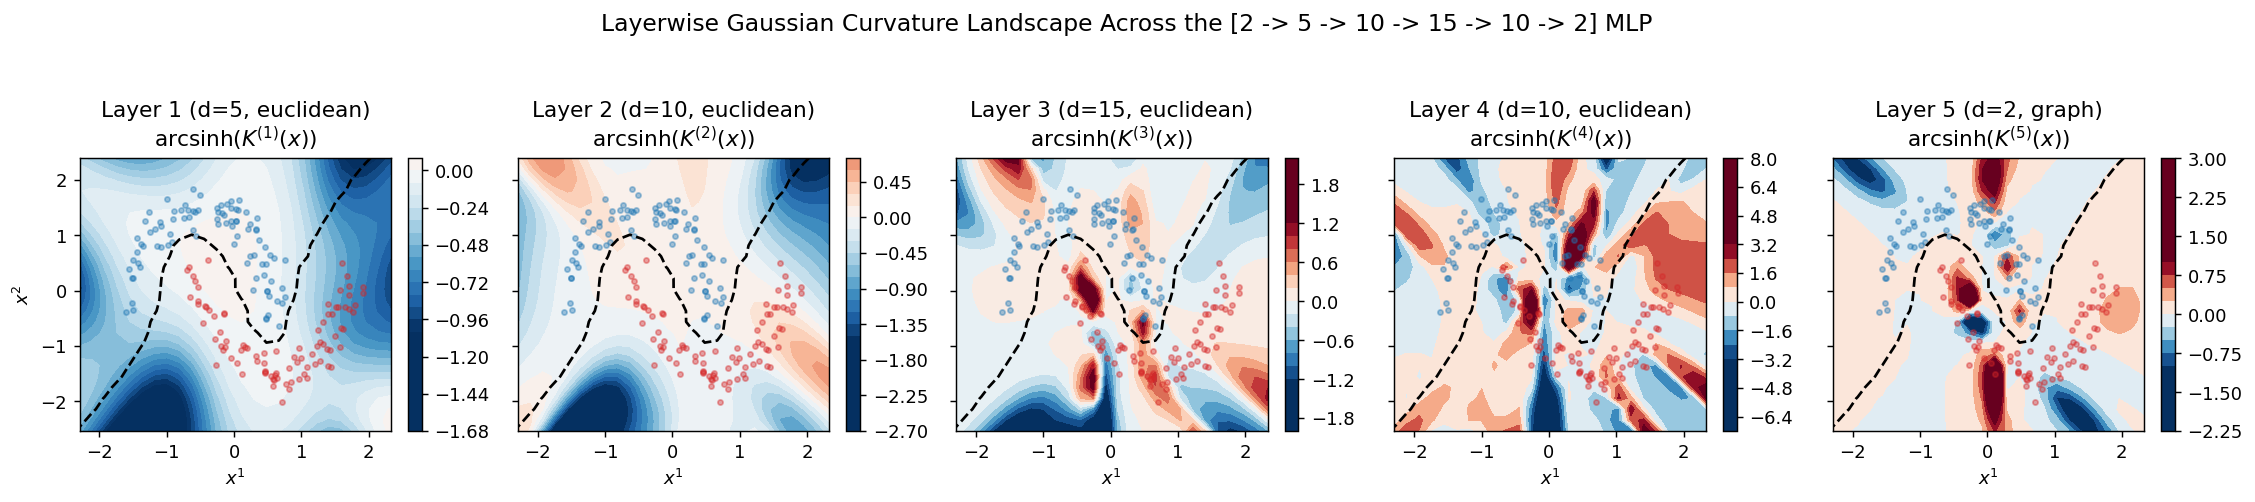

In [3]:
with torch.no_grad():
    probs_grid = torch.softmax(model(grid_pts), dim=-1)[:, 1].reshape(xx.shape).numpy()

fig, axes = plt.subplots(1, 5, figsize=(17.5, 3.7), sharex=True, sharey=True)
for idx, l_idx in enumerate(range(1, 6)):
    mode = "graph" if l_idx == 5 else "euclidean"
    geom = compute_layer_geometry(model, grid_pts, layer_idx=l_idx, metric_mode=mode, eps=1e-6)
    K_map = np.arcsinh(geom["K"].detach().numpy().reshape(xx.shape))
    vmax = max(np.percentile(np.abs(K_map), 96), 0.1)

    im = axes[idx].contourf(xx, yy, K_map, levels=22, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[idx].contour(xx, yy, probs_grid, levels=[0.5], colors="k", linewidths=1.5, linestyles="--")
    axes[idx].scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#1f77b4", s=8, alpha=0.4)
    axes[idx].scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#d62728", s=8, alpha=0.4)
    axes[idx].set_title(f"Layer {l_idx} (d={model.layer_dims[l_idx]}, {mode})\n$\mathrm{{arcsinh}}(K^{{({l_idx})}}(x))$")
    axes[idx].set_xlabel("$x^1$")
    plt.colorbar(im, ax=axes[idx], fraction=0.046)

axes[0].set_ylabel("$x^2$")
plt.suptitle("Layerwise Gaussian Curvature Landscape Across the [2 -> 5 -> 10 -> 15 -> 10 -> 2] MLP", y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

## 3. Evolution of Layerwise Curvature & Christoffel Symbol Norms Across Training Epochs
We track how the mean magnitude of Gaussian curvature $\mathbb{E}[|K^{(\ell)}(x)|]$ and Christoffel connection norm $\mathbb{E}[\|\Gamma^{(\ell)}(x)\|_F]$ evolve across layers $\ell \in \{1,\dots,5\}$ from initialization ($t=0$) to convergence ($t=200$), contrasting interior class points against decision-boundary points ($|P(y=1|x) - 0.5| < 0.15$).

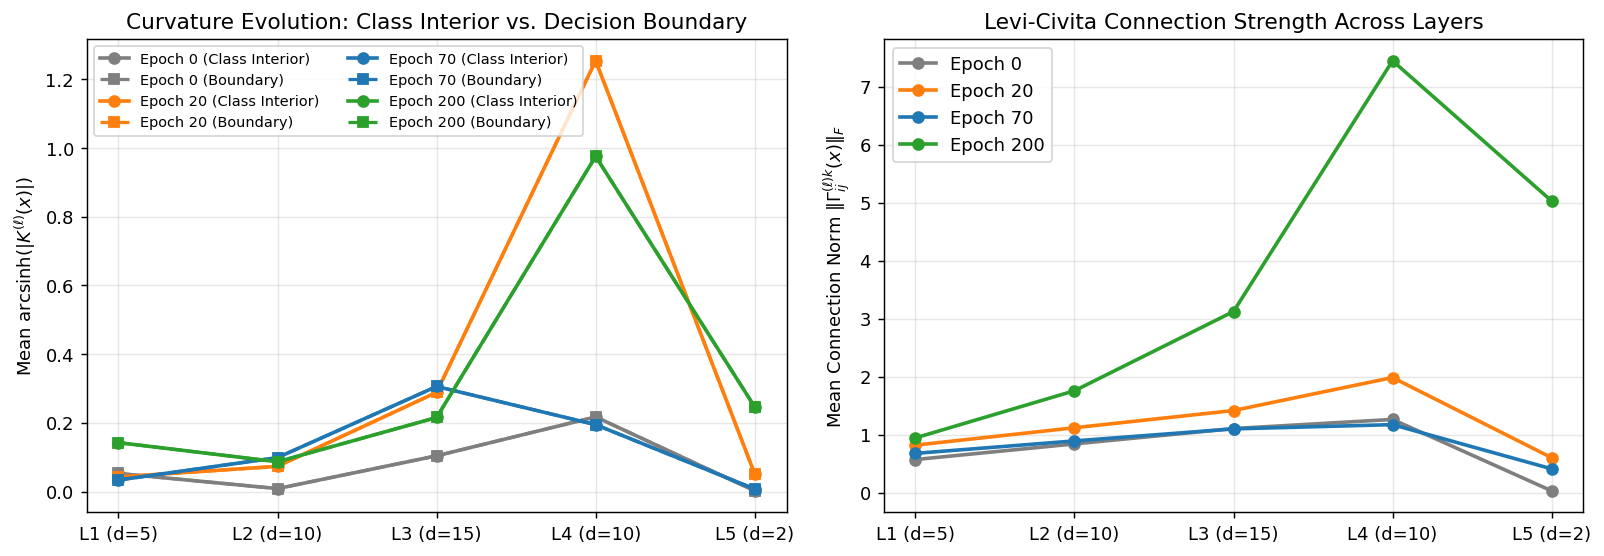

In [4]:
with torch.no_grad():
    p_tr = torch.softmax(model(X_train), dim=-1)[:, 1]
    boundary_mask = (p_tr - 0.5).abs() < 0.20
    interior_mask = ~boundary_mask

probe = MoonsMLP(layer_dims=(2, 5, 10, 15, 10, 2), activation="tanh", seed=42)
epochs_list = [0, 20, 70, 200]
layers_list = [1, 2, 3, 4, 5]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
colors = ["#7f7f7f", "#ff7f0e", "#1f77b4", "#2ca02c"]

for ep, col in zip(epochs_list, colors):
    probe.load_state_dict(epoch_snapshots[ep])
    k_int, k_bnd, gamma_norms = [], [], []
    for l_idx in layers_list:
        mode = "graph" if l_idx == 5 else "euclidean"
        g_tr = compute_layer_geometry(probe, X_train, layer_idx=l_idx, metric_mode=mode, eps=1e-6)
        k_abs = torch.arcsinh(g_tr["K"].abs()).detach()
        k_int.append(k_abs[interior_mask].mean().item())
        k_bnd.append(k_abs[boundary_mask].mean().item() if boundary_mask.any() else k_abs.mean().item())
        gamma_norms.append(g_tr["christoffel"].flatten(1).norm(dim=1).mean().item())

    axes[0].plot(layers_list, k_int, marker="o", lw=2, color=col, label=f"Epoch {ep} (Class Interior)")
    axes[0].plot(layers_list, k_bnd, marker="s", lw=1.8, ls="--", color=col, label=f"Epoch {ep} (Boundary)")
    axes[1].plot(layers_list, gamma_norms, marker="o", lw=2, color=col, label=f"Epoch {ep}")

axes[0].set_xticks(layers_list)
axes[0].set_xticklabels([f"L{l} (d={model.layer_dims[l]})" for l in layers_list])
axes[0].set_ylabel("Mean $\mathrm{arcsinh}(|K^{(\ell)}(x)|)$")
axes[0].set_title("Curvature Evolution: Class Interior vs. Decision Boundary")
axes[0].legend(fontsize=8, ncol=2)
axes[0].grid(alpha=0.3)

axes[1].set_xticks(layers_list)
axes[1].set_xticklabels([f"L{l} (d={model.layer_dims[l]})" for l in layers_list])
axes[1].set_ylabel("Mean Connection Norm $\|\Gamma^{(\ell)k}_{ij}(x)\|_F$")
axes[1].set_title("Levi-Civita Connection Strength Across Layers")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Layerwise Log Volume Landscape Across Network Depth

Alongside curvature $K^{(\ell)}(x)$, the pullback metric $g^{(\ell)}_{ij}(x; \theta)$ defines the **local Riemannian log-volume density**:
$$\log \rho_{\text{vol}}^{(\ell)}(x; \theta) = \log\sqrt{\det g^{(\ell)}(x; \theta)} = \frac{1}{2}\log \det g^{(\ell)}(x; \theta)$$
where $\log\sqrt{\det g^{(\ell)}(x)} > 0$ indicates local area expansion, $\log\sqrt{\det g^{(\ell)}(x)} < 0$ indicates local area contraction, and $\log\sqrt{\det g^{(\ell)}(x)} = 0$ is the equiareal contour ($\det g^{(\ell)} = 1$).

Below we visualize:
1. The 2D spatial landscape of $\log\sqrt{\det g^{(\ell)}(x)}$ across all five layers $\ell \in \{1, 2, 3, 4, 5\}$.
2. The evolution of $\mathbb{E}[\log\sqrt{\det g^{(\ell)}(x)}]$ across layers $\ell = 1 \to 5$ and training epochs $t \in \{0, 20, 70, 200\}$, contrasting class interior points against the decision boundary and comparing Class $0$ vs. Class $1$.

Layer      Width       Min log Vol   Mean log Vol    Max log Vol   Boundary Mean
--------------------------------------------------------------------------------
Layer 1    d=5              -3.071         -1.202          0.112          -0.669
Layer 2    d=10             -3.279         -0.916          1.464          -0.082
Layer 3    d=15             -2.426         -0.365          3.034           0.400
Layer 4    d=10             -5.425         -1.224          3.539          -0.354
Layer 5    d=2              -7.135         -1.456          4.282          -0.720


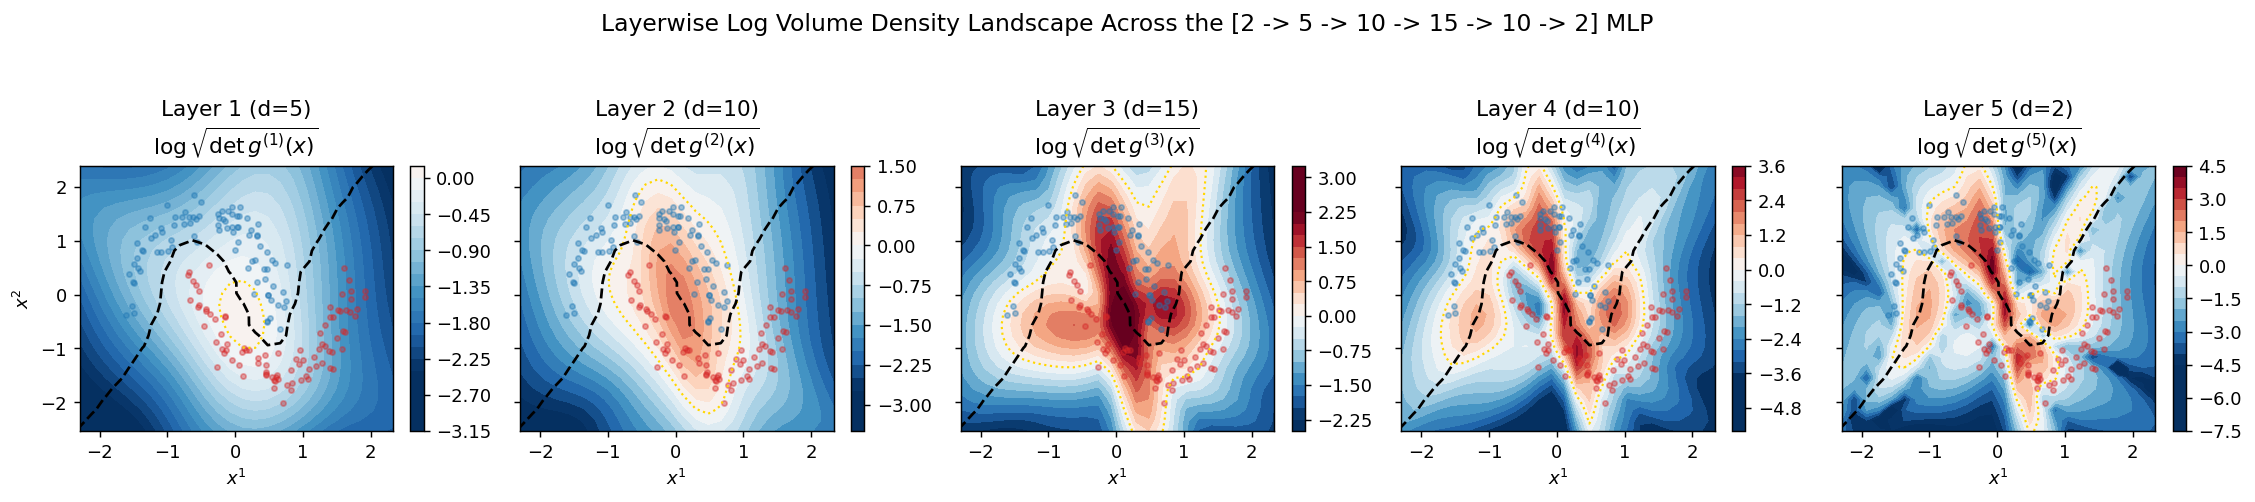

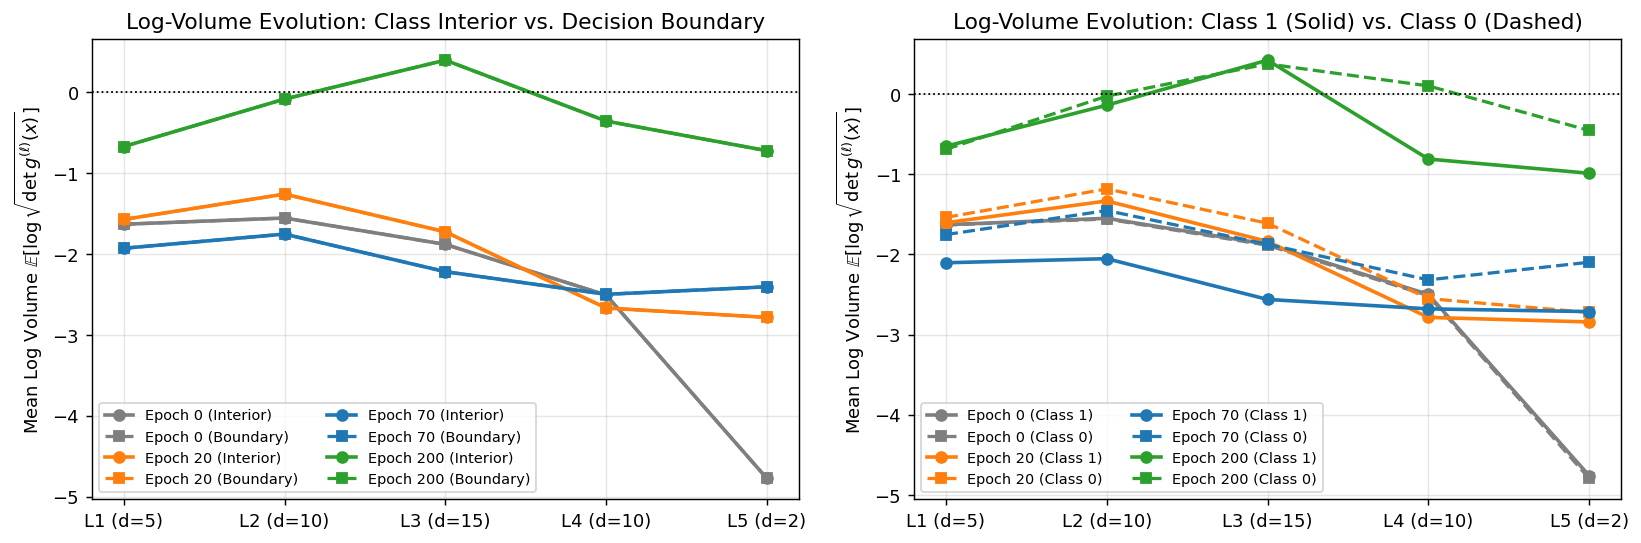

In [5]:
from src.geometry import compute_layer_pullback_metric, compute_metric_spectrum

fig, axes = plt.subplots(1, 5, figsize=(17.5, 3.7), sharex=True, sharey=True)
print(f"{'Layer':<10} {'Width':<8} {'Min log Vol':>14} {'Mean log Vol':>14} {'Max log Vol':>14} {'Boundary Mean':>15}")
print("-" * 80)

for idx, l_idx in enumerate(layers_list):
    g_grid = compute_layer_pullback_metric(model, grid_pts, layer_idx=l_idx, metric_mode="euclidean", eps=1e-7)
    log_vol_grid = (0.5 * torch.log(torch.clamp(torch.linalg.det(g_grid), min=1e-12))).detach().numpy().reshape(xx.shape)
    vmax_v = max(np.percentile(np.abs(log_vol_grid), 96), 0.2)

    g_tr_l = compute_layer_pullback_metric(model, X_train, layer_idx=l_idx, metric_mode="euclidean", eps=1e-7)
    log_vol_tr = (0.5 * torch.log(torch.clamp(torch.linalg.det(g_tr_l), min=1e-12))).detach()
    bnd_mean = log_vol_tr[boundary_mask].mean().item() if boundary_mask.any() else log_vol_tr.mean().item()

    print(
        f"Layer {l_idx:<4d} d={model.layer_dims[l_idx]:<6d} "
        f"{log_vol_grid.min():14.3f} {log_vol_grid.mean():14.3f} {log_vol_grid.max():14.3f} {bnd_mean:15.3f}"
    )

    im = axes[idx].contourf(xx, yy, log_vol_grid, levels=22, cmap="RdBu_r", vmin=-vmax_v, vmax=vmax_v)
    axes[idx].contour(xx, yy, log_vol_grid, levels=[0.0], colors="gold", linewidths=1.2, linestyles=":")
    axes[idx].contour(xx, yy, probs_grid, levels=[0.5], colors="k", linewidths=1.5, linestyles="--")
    axes[idx].scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#1f77b4", s=8, alpha=0.4)
    axes[idx].scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#d62728", s=8, alpha=0.4)
    axes[idx].set_title(f"Layer {l_idx} (d={model.layer_dims[l_idx]})\n$\log\sqrt{{\det g^{{({l_idx})}}(x)}}$")
    axes[idx].set_xlabel("$x^1$")
    plt.colorbar(im, ax=axes[idx], fraction=0.046)

axes[0].set_ylabel("$x^2$")
plt.suptitle("Layerwise Log Volume Density Landscape Across the [2 -> 5 -> 10 -> 15 -> 10 -> 2] MLP", y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

# Track Log-Volume evolution across training epochs (Interior vs Boundary & Class 0 vs Class 1)
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.3))
for ep, col in zip(epochs_list, colors):
    probe.load_state_dict(epoch_snapshots[ep])
    lv_int, lv_bnd, lv_c0, lv_c1 = [], [], [], []
    for l_idx in layers_list:
        g_ep = compute_layer_pullback_metric(probe, X_train, layer_idx=l_idx, metric_mode="euclidean", eps=1e-7)
        lv = (0.5 * torch.log(torch.clamp(torch.linalg.det(g_ep), min=1e-12))).detach()
        lv_int.append(lv[interior_mask].mean().item())
        lv_bnd.append(lv[boundary_mask].mean().item() if boundary_mask.any() else lv.mean().item())
        lv_c0.append(lv[y_train == 0].mean().item())
        lv_c1.append(lv[y_train == 1].mean().item())

    axes[0].plot(layers_list, lv_int, "o-", lw=2, color=col, label=f"Epoch {ep} (Interior)")
    axes[0].plot(layers_list, lv_bnd, "s--", lw=1.8, color=col, label=f"Epoch {ep} (Boundary)")
    axes[1].plot(layers_list, lv_c1, "o-", lw=2, color=col, label=f"Epoch {ep} (Class 1)")
    axes[1].plot(layers_list, lv_c0, "s--", lw=1.8, color=col, label=f"Epoch {ep} (Class 0)")

for ax in axes:
    ax.axhline(0.0, color="k", lw=1.0, ls=":")
    ax.set_xticks(layers_list)
    ax.set_xticklabels([f"L{l} (d={model.layer_dims[l]})" for l in layers_list])
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean Log Volume $\mathbb{E}[\log\sqrt{\det g^{(\ell)}(x)}]$")
axes[0].set_title("Log-Volume Evolution: Class Interior vs. Decision Boundary")
axes[0].legend(fontsize=8, ncol=2)

axes[1].set_ylabel("Mean Log Volume $\mathbb{E}[\log\sqrt{\det g^{(\ell)}(x)}]$")
axes[1].set_title("Log-Volume Evolution: Class 1 (Solid) vs. Class 0 (Dashed)")
axes[1].legend(fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

## 5. Layerwise Metric Anisotropy Landscape Across Network Depth

To capture how each layer stretches space directionally (beyond isotropic area change), we examine two **metric anisotropy fields** across layers $\ell \in \{1, 2, 3, 4, 5\}$:
1. **Directional Metric Polarization**: $\log\!\big(g^{(\ell)}_{11}(x) / g^{(\ell)}_{22}(x)\big)$, measuring horizontal ($x^1$) versus vertical ($x^2$) metric dilation.
2. **Coordinate-Invariant Spectral Anisotropy**: $\log_{10}\!\big(\lambda_1(g^{(\ell)}(x)) / \lambda_2(g^{(\ell)}(x))\big)$, measuring the condition number (ratio of principal eigenvalues) of $g^{(\ell)}(x)$ and quantifying the formation of 1D singular foliation leaves (**Benfenati & Marta, 2023**).

Layer      Width     Mean log(g11/g22)  Mean log10(l1/l2)  Boundary log10(l1/l2)
--------------------------------------------------------------------------------
Layer 1    d=5                  +0.173              0.698                  0.572
Layer 2    d=10                 +0.386              1.012                  0.723
Layer 3    d=15                 +0.477              1.113                  0.683
Layer 4    d=10                 +0.652              1.955                  1.412
Layer 5    d=2                  +0.972              3.974                  3.595


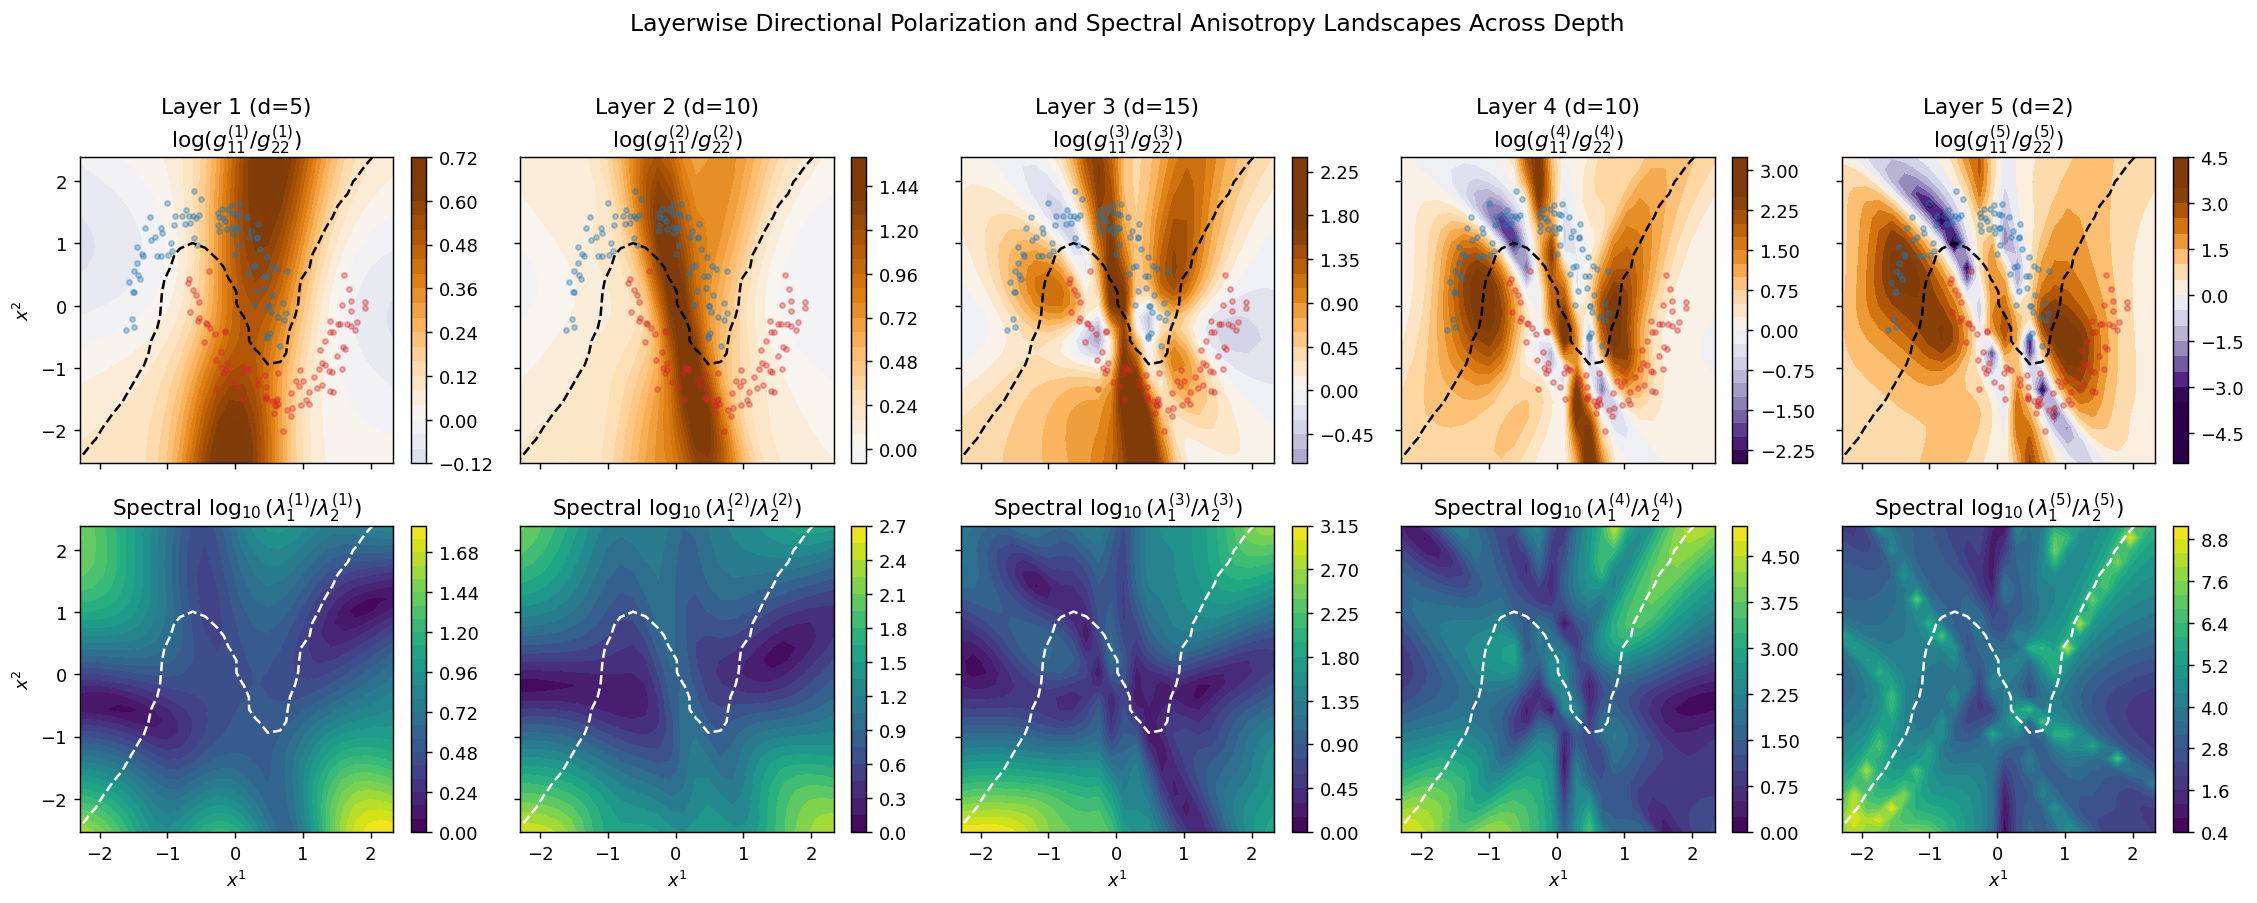

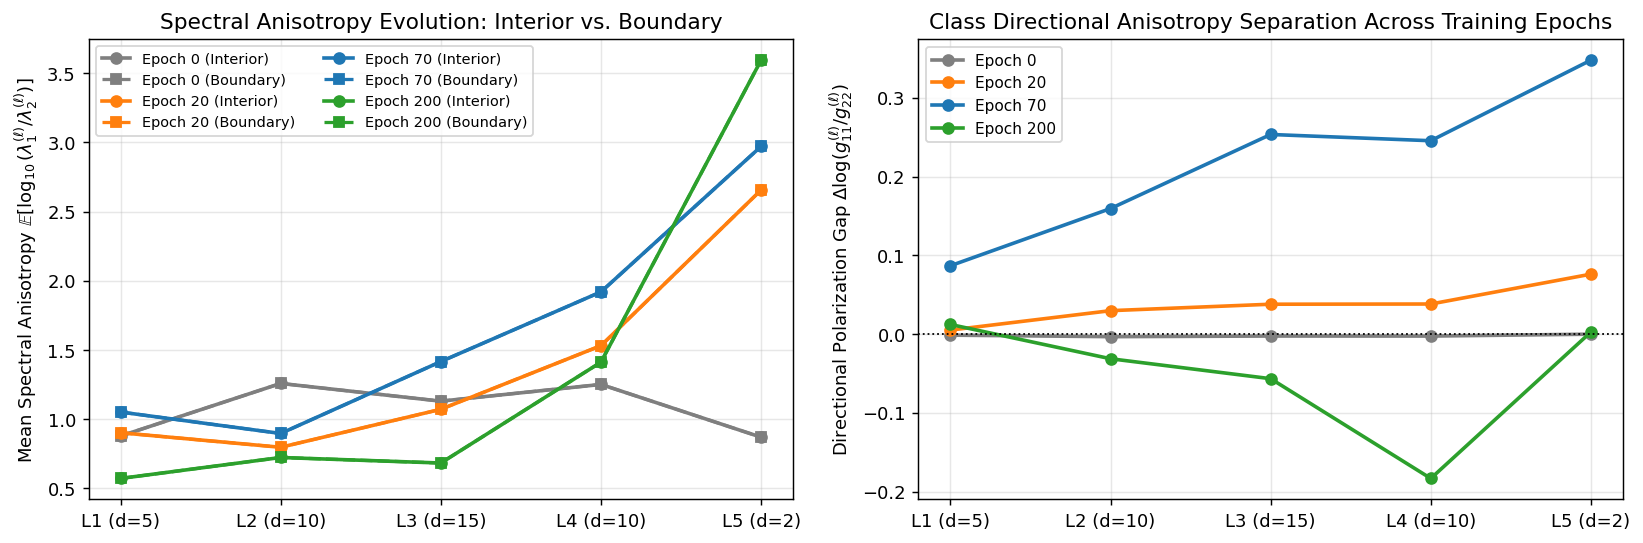

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(17.5, 6.8), sharex=True, sharey=True)
print(f"{'Layer':<10} {'Width':<8} {'Mean log(g11/g22)':>18} {'Mean log10(l1/l2)':>18} {'Boundary log10(l1/l2)':>22}")
print("-" * 80)

for idx, l_idx in enumerate(layers_list):
    g_grid_graph = compute_layer_pullback_metric(model, grid_pts, layer_idx=l_idx, metric_mode="graph")
    dir_aniso_grid = torch.log(g_grid_graph[:, 0, 0] / g_grid_graph[:, 1, 1]).detach().numpy().reshape(xx.shape)
    vmax_a = max(np.percentile(np.abs(dir_aniso_grid), 96), 0.15)

    g_grid_eucl = compute_layer_pullback_metric(model, grid_pts, layer_idx=l_idx, metric_mode="euclidean", eps=1e-7)
    _, _, cond_grid = compute_metric_spectrum(g_grid_eucl)
    spec_aniso_grid = torch.log10(torch.clamp(cond_grid, min=1.0)).detach().numpy().reshape(xx.shape)

    g_tr_eucl = compute_layer_pullback_metric(model, X_train, layer_idx=l_idx, metric_mode="euclidean", eps=1e-7)
    _, _, cond_tr = compute_metric_spectrum(g_tr_eucl)
    log_cond_tr = torch.log10(torch.clamp(cond_tr, min=1.0)).detach()
    bnd_cond = log_cond_tr[boundary_mask].mean().item() if boundary_mask.any() else log_cond_tr.mean().item()

    print(
        f"Layer {l_idx:<4d} d={model.layer_dims[l_idx]:<6d} "
        f"{dir_aniso_grid.mean():+18.3f} {spec_aniso_grid.mean():18.3f} {bnd_cond:22.3f}"
    )

    # Row 0: Directional polarization log(g11 / g22)
    im0 = axes[0, idx].contourf(xx, yy, dir_aniso_grid, levels=22, cmap="PuOr_r", vmin=-vmax_a, vmax=vmax_a)
    axes[0, idx].contour(xx, yy, probs_grid, levels=[0.5], colors="k", linewidths=1.4, linestyles="--")
    axes[0, idx].scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#1f77b4", s=8, alpha=0.35)
    axes[0, idx].scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#d62728", s=8, alpha=0.35)
    axes[0, idx].set_title(f"Layer {l_idx} (d={model.layer_dims[l_idx]})\n$\log(g^{{({l_idx})}}_{{11}} / g^{{({l_idx})}}_{{22}})$")
    plt.colorbar(im0, ax=axes[0, idx], fraction=0.046)

    # Row 1: Spectral condition number log10(lambda_1 / lambda_2)
    im1 = axes[1, idx].contourf(xx, yy, spec_aniso_grid, levels=22, cmap="viridis")
    axes[1, idx].contour(xx, yy, probs_grid, levels=[0.5], colors="white", linewidths=1.4, linestyles="--")
    axes[1, idx].set_title(f"Spectral $\log_{{10}}(\lambda_1^{{({l_idx})}} / \lambda_2^{{({l_idx})}})$")
    axes[1, idx].set_xlabel("$x^1$")
    plt.colorbar(im1, ax=axes[1, idx], fraction=0.046)

axes[0, 0].set_ylabel("$x^2$")
axes[1, 0].set_ylabel("$x^2$")
plt.suptitle("Layerwise Directional Polarization and Spectral Anisotropy Landscapes Across Depth", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

# Track Spectral and Directional Anisotropy across training epochs
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.3))
for ep, col in zip(epochs_list, colors):
    probe.load_state_dict(epoch_snapshots[ep])
    spec_int, spec_bnd, dir_gap = [], [], []
    for l_idx in layers_list:
        g_ep_eucl = compute_layer_pullback_metric(probe, X_train, layer_idx=l_idx, metric_mode="euclidean", eps=1e-7)
        _, _, cond_ep = compute_metric_spectrum(g_ep_eucl)
        lc = torch.log10(torch.clamp(cond_ep, min=1.0)).detach()
        spec_int.append(lc[interior_mask].mean().item())
        spec_bnd.append(lc[boundary_mask].mean().item() if boundary_mask.any() else lc.mean().item())

        g_ep_graph = compute_layer_pullback_metric(probe, X_train, layer_idx=l_idx, metric_mode="graph").detach()
        lr = torch.log(g_ep_graph[:, 0, 0] / g_ep_graph[:, 1, 1])
        dir_gap.append((lr[y_train == 1].mean() - lr[y_train == 0].mean()).item())

    axes[0].plot(layers_list, spec_int, "o-", lw=2, color=col, label=f"Epoch {ep} (Interior)")
    axes[0].plot(layers_list, spec_bnd, "s--", lw=1.8, color=col, label=f"Epoch {ep} (Boundary)")
    axes[1].plot(layers_list, dir_gap, "o-", lw=2, color=col, label=f"Epoch {ep}")

axes[0].set_xticks(layers_list)
axes[0].set_xticklabels([f"L{l} (d={model.layer_dims[l]})" for l in layers_list])
axes[0].set_ylabel("Mean Spectral Anisotropy $\mathbb{E}[\log_{10}(\lambda_1^{(\ell)} / \lambda_2^{(\ell)})]$")
axes[0].set_title("Spectral Anisotropy Evolution: Interior vs. Boundary")
axes[0].legend(fontsize=8, ncol=2)
axes[0].grid(alpha=0.3)

axes[1].axhline(0.0, color="k", lw=1.0, ls=":")
axes[1].set_xticks(layers_list)
axes[1].set_xticklabels([f"L{l} (d={model.layer_dims[l]})" for l in layers_list])
axes[1].set_ylabel("Directional Polarization Gap $\Delta \log(g^{(\ell)}_{11} / g^{(\ell)}_{22})$")
axes[1].set_title("Class Directional Anisotropy Separation Across Training Epochs")
axes[1].legend(fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()